In [1]:

# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')


/Users/omarhashem/Documents/Codex/2026-10-18/re/work/audit_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Data Cleaning & Auditing

We first load and inspect the raw Formula 1 tables before applying any cleaning. Cleaning decisions will be based on issues identified through programmatic checks and visualizations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from pathlib import Path
import os

# Set F1_DATA_DIR for a local run; Kaggle uses the attached dataset by default.
BASE_PATH = Path(os.environ.get("F1_DATA_DIR", "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"))
OUTPUT_DIR = Path(os.environ.get("F1_OUTPUT_DIR", "/kaggle/working/person1_additions" if Path("/kaggle").exists() else "person1_additions"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


circuits_raw = pd.read_csv(f"{BASE_PATH}/circuits.csv")
constructors_raw = pd.read_csv(f"{BASE_PATH}/constructors.csv")
constructor_results_raw = pd.read_csv(f"{BASE_PATH}/constructor_results.csv")
constructor_standings_raw = pd.read_csv(f"{BASE_PATH}/constructor_standings.csv")
drivers_raw = pd.read_csv(f"{BASE_PATH}/drivers.csv")
driver_standings_raw = pd.read_csv(f"{BASE_PATH}/driver_standings.csv")
races_raw = pd.read_csv(f"{BASE_PATH}/races.csv")
results_raw = pd.read_csv(f"{BASE_PATH}/results.csv")
qualifying_raw = pd.read_csv(f"{BASE_PATH}/qualifying.csv")
lap_times_raw = pd.read_csv(f"{BASE_PATH}/lap_times.csv")
pit_stops_raw = pd.read_csv(f"{BASE_PATH}/pit_stops.csv")
sprint_results_raw = pd.read_csv(f"{BASE_PATH}/sprint_results.csv")
seasons_raw = pd.read_csv(f"{BASE_PATH}/seasons.csv")
status_raw = pd.read_csv(f"{BASE_PATH}/status.csv")

tables_raw = {
    "circuits": circuits_raw,
    "constructors": constructors_raw,
    "constructor_results": constructor_results_raw,
    "constructor_standings": constructor_standings_raw,
    "drivers": drivers_raw,
    "driver_standings": driver_standings_raw,
    "races": races_raw,
    "results": results_raw,
    "qualifying": qualifying_raw,
    "lap_times": lap_times_raw,
    "pit_stops": pit_stops_raw,
    "sprint_results": sprint_results_raw,
    "seasons": seasons_raw,
    "status": status_raw
}

print("Number of tables loaded:", len(tables_raw))


Number of tables loaded: 14


## 2. Initial EDA — Dataset Overview

We first inspect the size and structure of each table programmatically. This helps us understand the scale and grain of the relational dataset before cleaning.

In [3]:
overview = []

for name, df in tables_raw.items():
    overview.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "duplicate_rows": df.duplicated().sum()
    })

overview_df = pd.DataFrame(overview).sort_values("rows", ascending=False)

overview_df


,table,rows,columns,duplicate_rows
9,lap_times,589081,6,0
5,driver_standings,34863,7,0
7,results,26759,18,0
3,constructor_standings,13391,7,0
2,constructor_results,12625,5,0
10,pit_stops,11371,7,0
8,qualifying,10494,9,0
6,races,1125,18,0
4,drivers,861,9,0
11,sprint_results,360,16,0


### Observation

No table contains exact duplicate rows.

However, this does not guarantee that the required modeling grain is valid. The `results` table must still be checked separately for repeated `(raceId, driverId)` combinations, since historical shared-drive cases can create multiple rows for the same driver in one race.

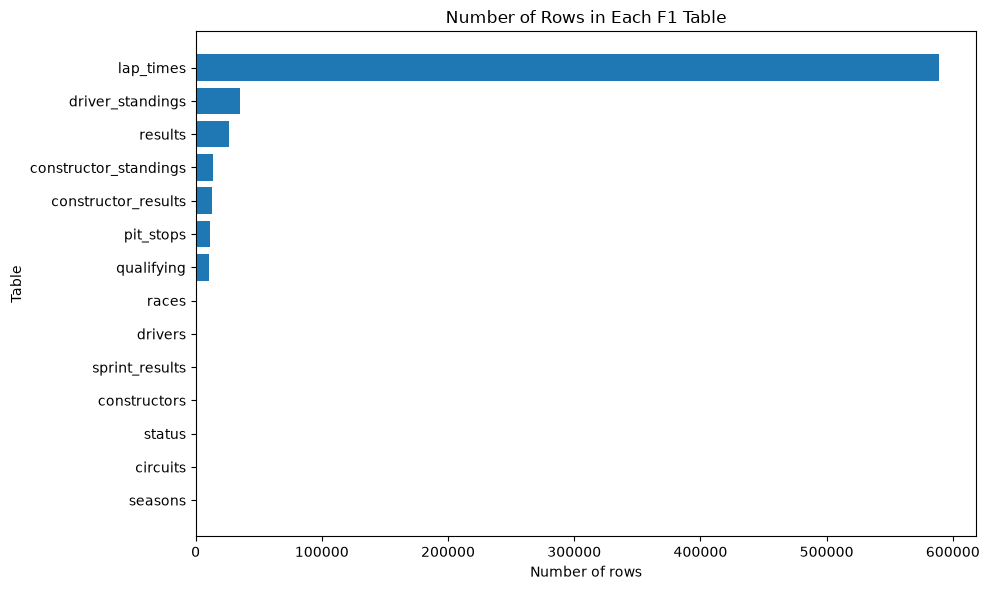

In [4]:
plt.figure(figsize=(10, 6))

plot_df = overview_df.sort_values("rows")

plt.barh(plot_df["table"], plot_df["rows"])

plt.xlabel("Number of rows")
plt.ylabel("Table")
plt.title("Number of Rows in Each F1 Table")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_raw_table_sizes.png", dpi=160, bbox_inches="tight")
plt.show()


### Observation

The dataset contains tables with very different sizes and grains. For example, event-level tables such as lap times contain many more rows than lookup tables such as circuits or constructors.

Therefore, cleaning and duplicate checks should be performed according to the meaning and key structure of each table rather than applying the same rule to all tables.

## 3. Missing Values and Sentinel Analysis

The dataset uses the literal value `\N` as a placeholder for missing data. We first identify where these sentinel values occur before cleaning so that the cleaning decision is based on observed missingness.

In [5]:
missing_summary = []

for name, df in tables_raw.items():
    for col in df.columns:
        sentinel_count = (df[col].astype(str) == r"\N").sum()

        if sentinel_count > 0:
            missing_summary.append({
                "table": name,
                "column": col,
                "sentinel_count": sentinel_count,
                "sentinel_pct": sentinel_count / len(df) * 100
            })

missing_summary_df = pd.DataFrame(missing_summary)

missing_summary_df.sort_values(
    "sentinel_pct",
    ascending=False
).head(30)


,table,column,sentinel_count,sentinel_pct
0,constructor_results,status,12608,99.865347
13,races,sprint_time,1110,98.666667
12,races,sprint_date,1107,98.400000
9,races,fp3_time,1072,95.288889
7,races,fp2_time,1057,93.955556
11,races,quali_time,1057,93.955556
5,races,fp1_time,1057,93.955556
8,races,fp3_date,1053,93.600000
1,drivers,number,802,93.147503
6,races,fp2_date,1035,92.000000


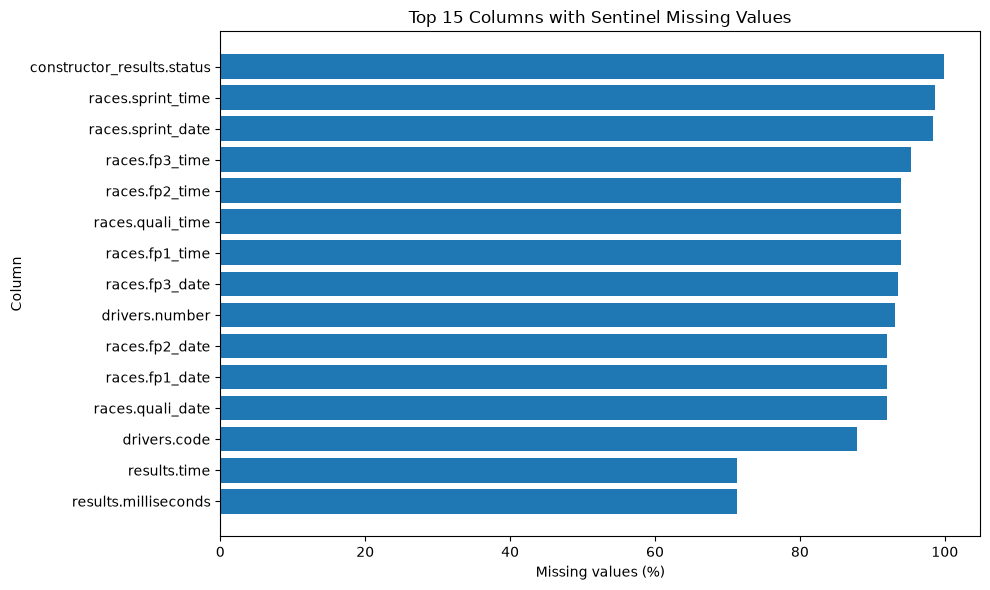

In [6]:
top_missing = (
    missing_summary_df
    .sort_values("sentinel_pct", ascending=False)
    .head(15)
    .copy()
)

top_missing["label"] = top_missing["table"] + "." + top_missing["column"]

plt.figure(figsize=(10, 6))

plt.barh(
    top_missing["label"][::-1],
    top_missing["sentinel_pct"][::-1]
)

plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.title("Top 15 Columns with Sentinel Missing Values")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_raw_missing_sentinels.png", dpi=160, bbox_inches="tight")
plt.show()


### Observation and Cleaning Decision

The amount of missing data differs across columns.

Some columns, such as `constructor_results.status` and several practice/sprint fields in `races`, have very high missingness, while others have moderate or low missingness.

Because the missing values have different meanings depending on the column, we will not apply one imputation method to every field.

At this cleaning stage, the literal `\N` sentinel values will be converted to proper missing values (`NaN`). Any later imputation or feature removal will be decided separately based on the meaning and usefulness of each feature.

In [7]:
tables_clean = {
    name: df.copy()
    for name, df in tables_raw.items()
}

for name, df in tables_clean.items():
    df.replace(r"\N", np.nan, inplace=True)


In [8]:
remaining_sentinels = 0

for name, df in tables_clean.items():
    remaining_sentinels += (df.astype(str) == r"\N").sum().sum()

print("Remaining literal \\N values:", remaining_sentinels)


Remaining literal \N values: 0


## 4. Semantic Typing

Some columns are stored as strings even though they represent dates or durations. We convert them into appropriate data types so they can be processed correctly later.

In [9]:
date_columns = {
    "drivers": ["dob"],
    "races": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"]
}

for table_name, columns in date_columns.items():
    for col in columns:
        if col in tables_clean[table_name].columns:
            tables_clean[table_name][col] = pd.to_datetime(
                tables_clean[table_name][col],
                errors="coerce"
            )


In [10]:
print(tables_clean["drivers"]["dob"].dtype)
print(tables_clean["races"]["date"].dtype)


datetime64[ns]
datetime64[ns]


### Justification

Date columns are converted to `datetime` so they can be sorted, compared, and used in time-based analysis correctly.

`errors="coerce"` is used so invalid or unavailable dates become missing values instead of causing errors.

### Duration Conversion

Some timing columns are stored as strings such as `1:23.456`. We convert them to numeric seconds so they can be analyzed and compared mathematically.

In [11]:
def time_to_seconds(value):
    if pd.isna(value):
        return np.nan

    parts = str(value).split(":")

    try:
        if len(parts) == 2:
            minutes, seconds = parts
            return float(minutes) * 60 + float(seconds)

        elif len(parts) == 3:
            hours, minutes, seconds = parts
            return (
                float(hours) * 3600
                + float(minutes) * 60
                + float(seconds)
            )

        else:
            return float(value)

    except ValueError:
        return np.nan


In [12]:
tables_clean["qualifying"]["q1_seconds"] = (
    tables_clean["qualifying"]["q1"].apply(time_to_seconds)
)

tables_clean["qualifying"]["q2_seconds"] = (
    tables_clean["qualifying"]["q2"].apply(time_to_seconds)
)

tables_clean["qualifying"]["q3_seconds"] = (
    tables_clean["qualifying"]["q3"].apply(time_to_seconds)
)

tables_clean["lap_times"]["time_seconds"] = (
    tables_clean["lap_times"]["time"].apply(time_to_seconds)
)

tables_clean["pit_stops"]["duration_seconds"] = (
    tables_clean["pit_stops"]["duration"].apply(time_to_seconds)
)


### Complete numeric and timing types

Sentinel-bearing numeric columns are explicitly converted to nullable integer or floating-point types. Fastest-lap durations in results and sprint results receive numeric seconds equivalents, and canonical milliseconds provide elapsed race time in seconds. Original timing text is preserved: `time` may contain relative gaps, so it is not blindly parsed as an absolute duration. These current-race outcome fields are for data quality and historical analysis only, and are not allowed prediction features. The audit stops on unexpected non-missing values that fail conversion.


In [13]:
# Columns with missing sentinels can otherwise remain text after replacement.
INTEGER_COLUMNS = {
    "drivers": ["number"],
    "results": ["number", "position", "milliseconds", "fastestLap", "rank"],
    "sprint_results": ["number", "position", "milliseconds", "fastestLap"],
}
FLOAT_COLUMNS = {"results": ["fastestLapSpeed"]}

def apply_semantic_types(tables):
    """Complete typing in an already-copied table dictionary; return parse audit."""
    audit = []
    def record(table, column, source, converted):
        bad = source.notna() & converted.isna()
        audit.append({"table": table, "column": column,
                      "nonmissing_input": int(source.notna().sum()),
                      "parse_failures": int(bad.sum()),
                      "examples": source.loc[bad].astype(str).head(3).tolist()})
        if bad.any():
            raise ValueError(f"Unexpected parse failures in {table}.{column}: {audit[-1]['examples']}")
    for table, columns in INTEGER_COLUMNS.items():
        for column in columns:
            if column not in tables[table]:
                continue
            source = tables[table][column]
            converted = pd.to_numeric(source, errors="coerce")
            record(table, column, source, converted)
            tables[table][column] = converted.astype("Int64")
    for table, columns in FLOAT_COLUMNS.items():
        for column in columns:
            source = tables[table][column]
            converted = pd.to_numeric(source, errors="coerce")
            record(table, column, source, converted)
            tables[table][column] = converted.astype("Float64")
    for table in ["results", "sprint_results"]:
        source = tables[table]["fastestLapTime"]
        converted = source.apply(time_to_seconds)
        record(table, "fastestLapTime_seconds", source, converted)
        tables[table]["fastestLapTime_seconds"] = converted.astype("Float64")
        # results.time mixes winner elapsed times and relative gaps (e.g. +5.123).
        # The canonical milliseconds field already records elapsed race time.
        # Keep the original text; do not interpret a gap as elapsed race time.
        tables[table]["elapsed_time_seconds"] = tables[table]["milliseconds"].astype("Float64") / 1000
    return pd.DataFrame(audit)

semantic_type_audit = apply_semantic_types(tables_clean)
display(semantic_type_audit)
semantic_type_audit.to_csv(OUTPUT_DIR / "semantic_type_audit.csv", index=False)
print("Remaining timing/numeric fields converted; unexpected parse failures:", semantic_type_audit["parse_failures"].sum())

# Audit the original date/lap/pit-duration conversions as well.
conversion_rows = []
for table, columns in date_columns.items():
    for column in columns:
        source = tables_raw[table][column].replace(r"\N", np.nan)
        failures = source.notna() & tables_clean[table][column].isna()
        conversion_rows.append({"table": table, "column": column, "parse_failures": int(failures.sum())})
for table, mapping in {"qualifying": {"q1": "q1_seconds", "q2": "q2_seconds", "q3": "q3_seconds"}, "lap_times": {"time": "time_seconds"}, "pit_stops": {"duration": "duration_seconds"}}.items():
    for original, converted in mapping.items():
        source = tables_raw[table][original].replace(r"\N", np.nan)
        failures = source.notna() & tables_clean[table][converted].isna()
        conversion_rows.append({"table": table, "column": converted, "parse_failures": int(failures.sum())})
conversion_audit = pd.DataFrame(conversion_rows)
assert conversion_audit["parse_failures"].eq(0).all(), "Date or duration parse failures need review"
conversion_audit.to_csv(OUTPUT_DIR / "date_duration_parse_audit.csv", index=False)


,table,column,nonmissing_input,parse_failures,examples
0,drivers,number,59,0,[]
1,results,number,26753,0,[]
2,results,position,15806,0,[]
3,results,milliseconds,7680,0,[]
4,results,fastestLap,8252,0,[]
5,results,rank,8510,0,[]
6,sprint_results,number,360,0,[]
7,sprint_results,position,345,0,[]
8,sprint_results,milliseconds,340,0,[]
9,sprint_results,fastestLap,351,0,[]


Remaining timing/numeric fields converted; unexpected parse failures: 0


In [14]:
tables_clean["qualifying"][
    ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
].head(10)


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


### Observation

The qualifying time strings were successfully converted to numeric seconds while missing values remained as `NaN`.

This makes the timing data easier to compare and use in later numerical analysis without inventing values for missing sessions.

## 5. Driver-Race Duplicate Check

The final modeling table must contain one row for each driver in each race. Therefore, we check whether the combination `(raceId, driverId)` is unique in the `results` table.

In [15]:
driver_race_counts = (
    tables_clean["results"]
    .groupby(["raceId", "driverId"])
    .size()
    .reset_index(name="count")
)

duplicate_driver_races = driver_race_counts[
    driver_race_counts["count"] > 1
]

print(
    "Number of duplicated driver-race combinations:",
    len(duplicate_driver_races)
)

duplicate_driver_races.head()


Number of duplicated driver-race combinations: 85


,raceId,driverId,count
13659,540,229,2
17821,717,373,2
18222,733,465,2
18445,742,475,2
18532,745,418,2


In [16]:
duplicate_details = (
    tables_clean["results"]
    .merge(
        duplicate_driver_races[["raceId", "driverId"]],
        on=["raceId", "driverId"],
        how="inner"
    )
    .merge(
        tables_clean["races"][["raceId", "year", "name"]],
        on="raceId",
        how="left"
    )
)

duplicate_by_year = (
    duplicate_details[
        ["year", "raceId", "driverId"]
    ]
    .drop_duplicates()
    .groupby("year")
    .size()
)

duplicate_by_year


year
1950     4
1951     4
1952     3
1953    14
1954    16
1955    15
1956    12
1957     8
1958     3
1960     1
1961     2
1962     1
1964     1
1978     1
dtype: int64

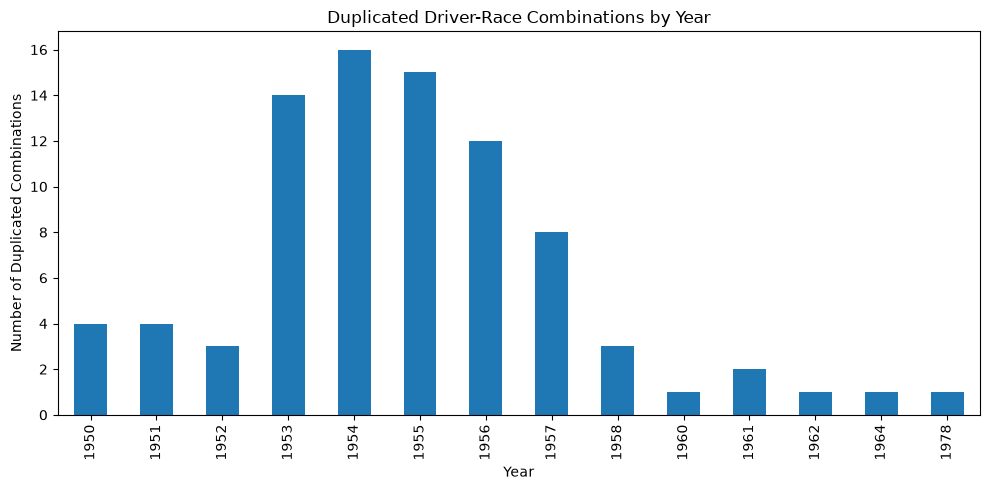

In [17]:
plt.figure(figsize=(10, 5))

duplicate_by_year.plot(kind="bar")

plt.title("Duplicated Driver-Race Combinations by Year")
plt.xlabel("Year")
plt.ylabel("Number of Duplicated Combinations")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_duplicate_groups_by_year.png", dpi=160, bbox_inches="tight")
plt.show()


### Observation

The duplicated driver-race combinations are concentrated mainly in the earlier Formula 1 seasons.

This matches the historical shared-drive issue, where a driver could appear more than once in the same race after switching cars.

Since the final modeling table requires one row per `(raceId, driverId)`, a consistent rule is needed to keep only one record for each duplicated pair.

### Duplicate Resolution Rule

Most duplicated `(raceId, driverId)` combinations occur in early Formula 1 seasons and are related to historical shared-drive cases.

To keep one row per driver and race without using post-race information, duplicates are resolved using the starting grid:

- Rows with a valid non-zero grid position are preferred.
- If multiple valid rows remain, the row with the lowest grid position is kept.
- `resultId` is used only as a tie-breaker.

`positionOrder` is not used for duplicate resolution because it is a post-race outcome and could introduce data leakage.

In [18]:
results_clean = tables_clean["results"].copy()

results_clean["valid_grid"] = results_clean["grid"] > 0

results_clean = (
    results_clean
    .sort_values(
        by=["raceId", "driverId", "valid_grid", "grid", "resultId"],
        ascending=[True, True, False, True, True]
    )
    .drop_duplicates(
        subset=["raceId", "driverId"],
        keep="first"
    )
    .drop(columns="valid_grid")
)

tables_clean["results"] = results_clean


In [19]:
remaining_duplicates = (
    tables_clean["results"]
    .duplicated(subset=["raceId", "driverId"])
    .sum()
)

print("Remaining duplicated driver-race combinations:", remaining_duplicates)
print("Rows before:", len(results_raw))
print("Rows after:", len(tables_clean["results"]))


Remaining duplicated driver-race combinations: 0
Rows before: 26759
Rows after: 26668


### Result

After applying the duplicate-resolution rule, no duplicated `(raceId, driverId)` combinations remain.

The `results` table decreased from 26,759 to 26,668 rows, giving one record per driver per race as required.

## 6. Primary Key Auditing

We verify that the expected primary key of each table is unique and contains no missing values. For tables without a single identifier column, the appropriate composite key is checked.

In [20]:
primary_keys = {
    "circuits": ["circuitId"],
    "constructors": ["constructorId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "drivers": ["driverId"],
    "driver_standings": ["driverStandingsId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "qualifying": ["qualifyId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "sprint_results": ["resultId"],
    "seasons": ["year"],
    "status": ["statusId"]
}

pk_audit = []

for table_name, key_cols in primary_keys.items():
    df = tables_clean[table_name]

    missing_keys = df[key_cols].isna().any(axis=1).sum()
    duplicate_keys = df.duplicated(subset=key_cols).sum()

    pk_audit.append({
        "table": table_name,
        "key": ", ".join(key_cols),
        "missing_key_rows": missing_keys,
        "duplicate_key_rows": duplicate_keys
    })

pk_audit_df = pd.DataFrame(pk_audit)

display(pk_audit_df)

assert not pk_audit_df[["missing_key_rows", "duplicate_key_rows"]].to_numpy().any(), "Primary-key validation failed"


,table,key,missing_key_rows,duplicate_key_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId, driverId, lap",0,0


### Observation

All expected primary keys are complete and unique.

No table contains missing key values or duplicated primary/composite keys, so the key structure is internally consistent after cleaning.

## 7. Foreign Key Auditing

We check whether foreign-key values in child tables can be matched to the corresponding parent tables.

This verifies that the relational tables can be joined consistently without unmatched identifiers.

In [21]:
foreign_keys = [
    ("races", "year", "seasons", "year"),
    ("races", "circuitId", "circuits", "circuitId"),

    ("results", "raceId", "races", "raceId"),
    ("results", "driverId", "drivers", "driverId"),
    ("results", "constructorId", "constructors", "constructorId"),
    ("results", "statusId", "status", "statusId"),

    ("qualifying", "raceId", "races", "raceId"),
    ("qualifying", "driverId", "drivers", "driverId"),
    ("qualifying", "constructorId", "constructors", "constructorId"),

    ("lap_times", "raceId", "races", "raceId"),
    ("lap_times", "driverId", "drivers", "driverId"),

    ("pit_stops", "raceId", "races", "raceId"),
    ("pit_stops", "driverId", "drivers", "driverId"),

    ("driver_standings", "raceId", "races", "raceId"),
    ("driver_standings", "driverId", "drivers", "driverId"),

    ("constructor_results", "raceId", "races", "raceId"),
    ("constructor_results", "constructorId", "constructors", "constructorId"),

    ("constructor_standings", "raceId", "races", "raceId"),
    ("constructor_standings", "constructorId", "constructors", "constructorId"),

    ("sprint_results", "raceId", "races", "raceId"),
    ("sprint_results", "driverId", "drivers", "driverId"),
    ("sprint_results", "constructorId", "constructors", "constructorId"),
    ("sprint_results", "statusId", "status", "statusId")
]

fk_audit = []

for child_table, child_col, parent_table, parent_col in foreign_keys:
    child_values = tables_clean[child_table][child_col]
    parent_values = tables_clean[parent_table][parent_col]

    unmatched = (
        child_values.notna()
        & ~child_values.isin(parent_values)
    ).sum()

    fk_audit.append({
        "child_table": child_table,
        "foreign_key": child_col,
        "parent_table": parent_table,
        "parent_key": parent_col,
        "unmatched_rows": unmatched
    })

fk_audit_df = pd.DataFrame(fk_audit)

display(fk_audit_df)

assert fk_audit_df["unmatched_rows"].eq(0).all(), "Foreign-key validation failed"


,child_table,foreign_key,parent_table,parent_key,unmatched_rows
0,races,year,seasons,year,0
1,races,circuitId,circuits,circuitId,0
2,results,raceId,races,raceId,0
3,results,driverId,drivers,driverId,0
4,results,constructorId,constructors,constructorId,0
5,results,statusId,status,statusId,0
6,qualifying,raceId,races,raceId,0
7,qualifying,driverId,drivers,driverId,0
8,qualifying,constructorId,constructors,constructorId,0
9,lap_times,raceId,races,raceId,0


### Observation

All checked foreign keys successfully match their corresponding parent-table keys.

No unmatched foreign-key values were found, which indicates that the relational links between the cleaned tables are consistent.

## 8. Post-Cleaning Verification

After cleaning, we verify that the main data-quality issues identified earlier have been resolved.

In [22]:
before_after = pd.DataFrame({
    "check": [
        "Literal sentinel values",
        "Duplicated (raceId, driverId)"
    ],
    "before": [
        sum(
            (df.astype(str) == r"\N").sum().sum()
            for df in tables_raw.values()
        ),
        int((tables_raw["results"].groupby(["raceId", "driverId"]).size() > 1).sum())
    ],
    "after": [
        sum(
            (df.astype(str) == r"\N").sum().sum()
            for df in tables_clean.values()
        ),
        tables_clean["results"]
        .duplicated(subset=["raceId", "driverId"])
        .sum()
    ]
})

before_after


,check,before,after
0,Literal sentinel values,160076,0
1,"Duplicated (raceId, driverId)",85,0


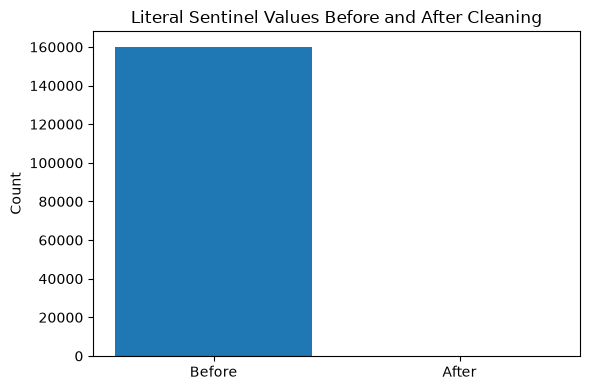

In [23]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Before", "After"],
    [before_after.loc[0, "before"], before_after.loc[0, "after"]]
)

plt.ylabel("Count")
plt.title("Literal Sentinel Values Before and After Cleaning")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_sentinels_before_after.png", dpi=160, bbox_inches="tight")
plt.show()


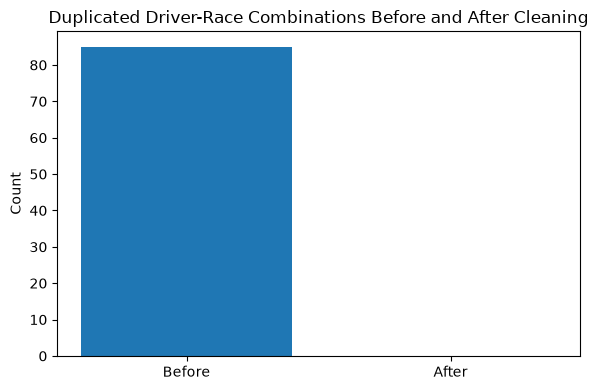

In [24]:
plt.figure(figsize=(6, 4))

plt.bar(
    ["Before", "After"],
    [before_after.loc[1, "before"], before_after.loc[1, "after"]]
)

plt.ylabel("Count")
plt.title("Duplicated Driver-Race Combinations Before and After Cleaning")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_duplicates_before_after.png", dpi=160, bbox_inches="tight")
plt.show()


### Final Cleaning Result

The literal `\N` sentinel values were successfully converted to proper missing values.

The duplicated `(raceId, driverId)` combinations were also resolved, leaving one row per driver per race.

Primary-key and foreign-key audits showed no remaining integrity problems in the checked tables.

### Cleaned Dataset Summary

The following tables are now ready for the next stages of analysis and feature engineering.

In [25]:
clean_summary = []

for name, df in tables_clean.items():
    clean_summary.append({
        "table": name,
        "rows": df.shape[0],
        "columns": df.shape[1]
    })

clean_summary_df = pd.DataFrame(clean_summary).sort_values(
    "rows",
    ascending=False
)

clean_summary_df


,table,rows,columns
9,lap_times,589081,7
5,driver_standings,34863,7
7,results,26668,20
3,constructor_standings,13391,7
2,constructor_results,12625,5
10,pit_stops,11371,8
8,qualifying,10494,12
6,races,1125,18
4,drivers,861,9
11,sprint_results,360,18


## 9. Additional checks — original cells above preserved

The original code and explanations above remain in their original order. These appended cells complete the missing work without changing the cleaned tables used by the rest of the team.

### 9.1 Columns and types

Inspect all 14 schemas programmatically so the raw-data overview explicitly covers column names and types.

In [26]:
from pathlib import Path
from IPython.display import display, Markdown

# OUTPUT_DIR is configured in the loading cell; every plot is saved there.

def save_plot(filename):
    plt.gcf().savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

schema_df = pd.DataFrame([
    {"table": name, "column": column, "raw_type": str(frame[column].dtype)}
    for name, frame in tables_raw.items() for column in frame.columns
])
with pd.option_context("display.max_rows", None):
    display(schema_df)


,table,column,raw_type
0,circuits,circuitId,int64
1,circuits,circuitRef,object
2,circuits,name,object
3,circuits,location,object
4,circuits,country,object
5,circuits,lat,float64
6,circuits,lng,float64
7,circuits,alt,int64
8,circuits,url,object
9,constructors,constructorId,int64


### 9.2 Calculated duplicate summary

The original summary above used the known value `85`. This additional summary calculates the counts directly instead. Duplicate groups and surplus rows are different quantities: one group with three records contributes one group and two surplus rows.

,check,before,after
0,Duplicated driver-race groups,85,0
1,Surplus driver-race rows,91,0
2,Results rows,26759,26668


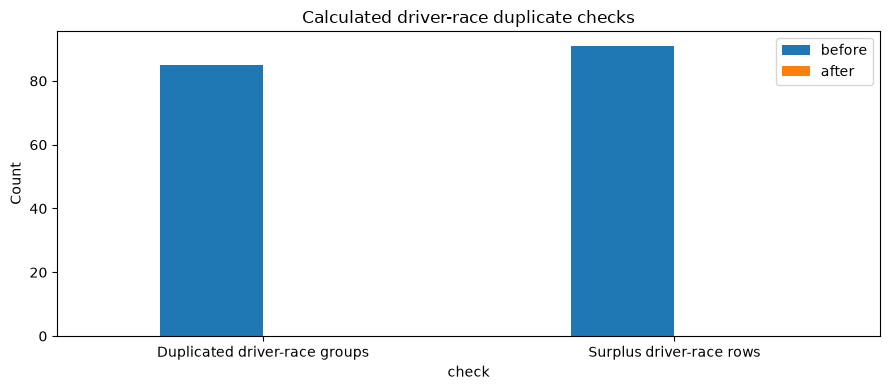

In [27]:
def duplicate_summary(frame):
    counts = frame.groupby(["raceId", "driverId"], dropna=False).size()
    return {"duplicate_groups": int((counts > 1).sum()),
            "surplus_rows": int((counts - 1).clip(lower=0).sum())}

raw_duplicates = duplicate_summary(tables_raw["results"])
clean_duplicates = duplicate_summary(tables_clean["results"])
before_after_calculated = pd.DataFrame({
    "check": ["Duplicated driver-race groups", "Surplus driver-race rows", "Results rows"],
    "before": [raw_duplicates["duplicate_groups"], raw_duplicates["surplus_rows"], len(tables_raw["results"])],
    "after": [clean_duplicates["duplicate_groups"], clean_duplicates["surplus_rows"], len(tables_clean["results"])]
})
display(before_after_calculated)
assert clean_duplicates["duplicate_groups"] == 0
ax = before_after_calculated.iloc[:2].set_index("check").plot.bar(rot=0, figsize=(9,4))
ax.set_ylabel("Count")
ax.set_title("Calculated driver-race duplicate checks")
plt.tight_layout()
save_plot("calculated_duplicate_checks.png")


### 9.3 Reusable cleaning function — same existing steps

This wraps the existing cleaning operations for reuse. The original inline cells are retained. The function uses the original `time_to_seconds()` and returns copies. Its output is checked against the existing `tables_clean`; the team handoff variable is not replaced.

In [28]:
DATE_COLUMNS = {'drivers': ['dob'], 'races': ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date']}
DURATION_COLUMNS = {'qualifying': {'q1': 'q1_seconds', 'q2': 'q2_seconds', 'q3': 'q3_seconds'}, 'lap_times': {'time': 'time_seconds'}, 'pit_stops': {'duration': 'duration_seconds'}}

def clean_tables(raw_tables):
    clean = {name: df.copy(deep=True) for name, df in raw_tables.items()}
    for df in clean.values():
        df.replace('\\N', np.nan, inplace=True)
    for name, columns in DATE_COLUMNS.items():
        for col in columns:
            if col in clean[name]:
                clean[name][col] = pd.to_datetime(clean[name][col], errors='coerce')
    for name, mappings in DURATION_COLUMNS.items():
        for original_col, new_col in mappings.items():
            clean[name][new_col] = clean[name][original_col].apply(time_to_seconds)
    apply_semantic_types(clean)
    results = clean['results'].copy()
    results['valid_grid'] = results['grid'] > 0
    clean['results'] = results.sort_values(['raceId', 'driverId', 'valid_grid', 'grid', 'resultId'], ascending=[True, True, False, True, True]).drop_duplicates(['raceId', 'driverId'], keep='first').drop(columns='valid_grid')
    return clean

reusable_check = clean_tables(tables_raw)
for name in tables_clean:
    pd.testing.assert_frame_equal(tables_clean[name], reusable_check[name])
print("Reusable function matches all 14 existing cleaned tables exactly.")
del reusable_check


Reusable function matches all 14 existing cleaned tables exactly.


### 9.4 Additional post-cleaning EDA

The existing before/after plots check cleaning success. The additional plot below compares effective missingness before and after cleaning: sentinel replacement converts missing markers to nulls without inventing information. The distribution comparison shows whether removing historical duplicate records changed season counts or starting-grid values. No additional cleaning or imputation is performed.

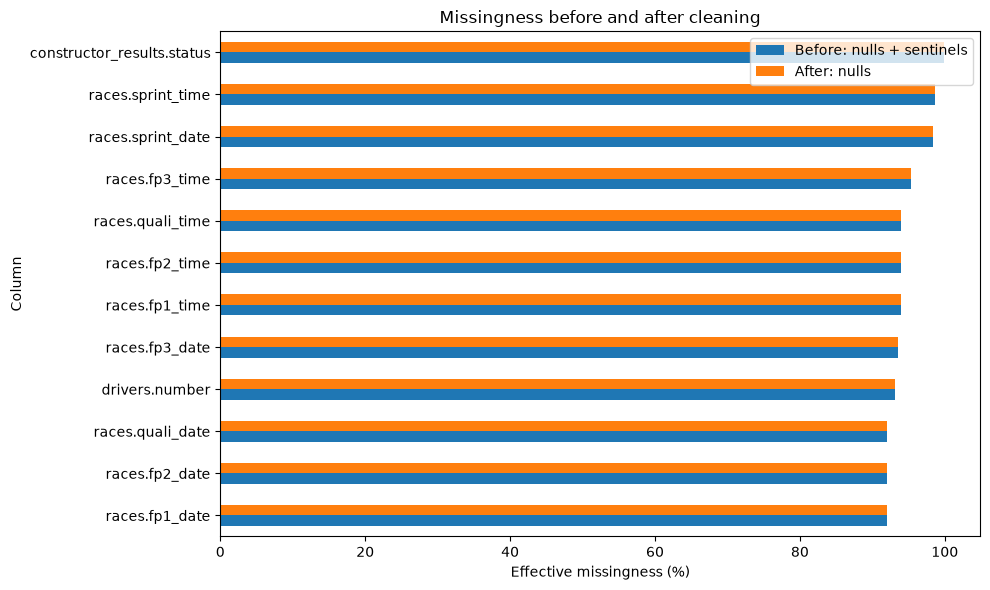

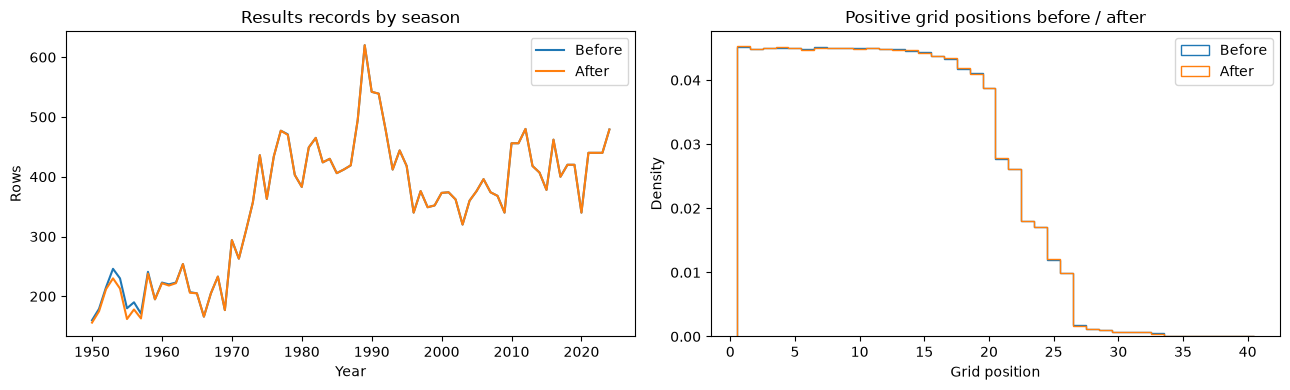

Rows removed: 91
Sentinels now appear as nulls; they were not imputed.


In [29]:
def effective_missingness(tables):
    return pd.DataFrame([
        {"table": name, "column": col,
         "missing_pct": (frame[col].isna() | frame[col].eq(r"\N").fillna(False)).mean() * 100}
        for name, frame in tables.items() for col in frame.columns
    ])

missing_compare = effective_missingness(tables_raw).merge(
    effective_missingness(tables_clean), on=["table", "column"], suffixes=("_before", "_after"))
top = missing_compare.nlargest(12, "missing_pct_before").sort_values("missing_pct_before")
plot = top.set_index(top["table"] + "." + top["column"])[["missing_pct_before", "missing_pct_after"]]
ax = plot.plot.barh(figsize=(10,6))
ax.set_xlabel("Effective missingness (%)")
ax.set_ylabel("Column")
ax.set_title("Missingness before and after cleaning")
ax.legend(["Before: nulls + sentinels", "After: nulls"])
plt.tight_layout()
save_plot("missingness_before_after.png")

fig, axes = plt.subplots(1, 2, figsize=(13,4))
for label, tables in [("Before", tables_raw), ("After", tables_clean)]:
    yearly = tables["results"].merge(tables["races"][["raceId", "year"]], on="raceId", validate="many_to_one").groupby("year").size()
    axes[0].plot(yearly.index, yearly.values, label=label)
    grid = pd.to_numeric(tables["results"]["grid"], errors="coerce")
    grid.loc[grid.gt(0)].plot.hist(bins=np.arange(.5,41.5,1), density=True, histtype="step", ax=axes[1], label=label)
axes[0].set(title="Results records by season", xlabel="Year", ylabel="Rows")
axes[1].set(title="Positive grid positions before / after", xlabel="Grid position", ylabel="Density")
for ax in axes: ax.legend()
fig.tight_layout()
save_plot("distributions_before_after.png")

print("Rows removed:", len(tables_raw["results"]) - len(tables_clean["results"]))
print("Sentinels now appear as nulls; they were not imputed.")


## 10. Q1 — Which circuits convert a front-row start into a podium most often?

**Question:** Does the circuit ranking change after the 2014 hybrid era? Distinguish qualifying from starting grid, which may differ because of penalties or weekend formats.

**Grain and joins:** join cleaned `results → races → circuits`, then left-join `qualifying` by `(raceId, driverId)`. Keep exactly one row per driver–race. Define podium as `positionOrder <= 3`.

**Two separate measures:** (1) actual front-row grid, `grid in {1, 2}`; (2) front-row qualifying, `qualifying_position in {1, 2}`. Each conversion rate is podium driver–race rows divided by front-row driver–race rows for that circuit and era. These are driver-level conversion rates, not the probability that at least one front-row car podiums.

**Missingness:** exclude unknown qualifying positions only from the qualifying calculation; never replace missing qualifying position with grid. Nonpositive grids do not count as front-row starts. Missing finishing outcomes are excluded and counted. A qualifying result need not equal the starting grid, especially on sprint weekends.

**Ranking policy:** show every circuit's numerator and denominator. Use at least 10 front-row observations per circuit–era for the displayed rankings to reduce very small-sample extremes. Compare rank movement only within the same set of circuits eligible in both eras. The full unscreened table and sensitivity summaries remain available. Wilson 95% intervals show uncertainty; rank movement alone is not proof of a meaningful change.

In [30]:
MIN_FRONT_ROW = 10

def answer_q1(tables, minimum=10):
    results = tables["results"][["raceId", "driverId", "grid", "positionOrder"]].copy()
    races = tables["races"][["raceId", "year", "circuitId"]]
    circuits = tables["circuits"][["circuitId", "name"]].rename(columns={"name": "circuit"})
    qualifying = tables["qualifying"][["raceId", "driverId", "position"]].rename(columns={"position": "qualifying_position"})
    if results.duplicated(["raceId", "driverId"]).any() or qualifying.duplicated(["raceId", "driverId"]).any():
        raise ValueError("Resolve duplicate driver–race keys before Q1")
    joined = (results.merge(races, on="raceId", validate="many_to_one")
              .merge(circuits, on="circuitId", validate="many_to_one")
              .merge(qualifying, on=["raceId", "driverId"], how="left", validate="one_to_one"))
    assert len(joined) == len(results), "Q1 join dropped result rows"
    for col in ["grid", "qualifying_position", "positionOrder"]:
        joined[col] = pd.to_numeric(joined[col], errors="coerce")
    joined["era"] = np.where(joined["year"] < 2014, "Before 2014", "2014 onward")
    joined["podium"] = joined["positionOrder"].le(3)
    summaries = []
    for definition, col in [("Starting grid", "grid"), ("Qualifying", "qualifying_position")]:
        subset = joined.loc[joined[col].isin([1, 2]) & joined["positionOrder"].notna()]
        stats = subset.groupby(["circuitId", "circuit", "era"], as_index=False).agg(
            front_row_observations=("podium", "size"), podiums=("podium", "sum"), races=("raceId", "nunique"))
        stats["definition"] = definition
        stats["conversion_rate"] = stats["podiums"] / stats["front_row_observations"]
        n, p = stats["front_row_observations"], stats["conversion_rate"]
        z = 1.96
        center = (p + z*z/(2*n)) / (1 + z*z/n)
        half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / (1 + z*z/n)
        stats["ci_low"], stats["ci_high"] = center-half, center+half
        stats["eligible"] = n.ge(minimum)
        summaries.append(stats)
    rates = pd.concat(summaries, ignore_index=True)
    return joined, rates

q1_joined, q1_rates = answer_q1(tables_clean, MIN_FRONT_ROW)
q1_coverage = q1_joined.groupby("era").agg(
    driver_race_rows=("driverId", "size"), known_qualifying=("qualifying_position", lambda s: int(s.gt(0).sum())),
    nonpositive_or_missing_grid=("grid", lambda s: int((s.isna() | s.le(0)).sum())),
    missing_outcome=("positionOrder", lambda s: int(s.isna().sum())))
q1_coverage["qualifying_coverage_pct"] = q1_coverage["known_qualifying"] / q1_coverage["driver_race_rows"] * 100
display(q1_coverage)
q1_disagreements = q1_joined.loc[q1_joined["qualifying_position"].gt(0) & q1_joined["grid"].gt(0)].copy()
q1_disagreements["front_row_membership_differs"] = q1_disagreements["grid"].isin([1,2]) != q1_disagreements["qualifying_position"].isin([1,2])
display(q1_disagreements.groupby("era")["front_row_membership_differs"].agg(["sum", "count", "mean"]))
with pd.option_context("display.max_rows", None):
    display(q1_rates.sort_values(["definition", "era", "conversion_rate"], ascending=[True, True, False]))


,driver_race_rows,known_qualifying,nonpositive_or_missing_grid,missing_outcome,qualifying_coverage_pct
era,,,,,
2014 onward,4626,4610,79,0,99.654129
Before 2014,22042,5884,1556,0,26.694492


,sum,count,mean
era,,,
2014 onward,54,4533,0.011913
Before 2014,18,5874,0.003064


,circuitId,circuit,era,front_row_observations,podiums,races,definition,conversion_rate,ci_low,ci_high,eligible
159,75,Autódromo Internacional do Algarve,2014 onward,4,4,2,Qualifying,1.000000,0.510100,1.000000,False
160,76,Autodromo Internazionale del Mugello,2014 onward,2,2,1,Qualifying,1.000000,0.342372,1.000000,False
163,79,Miami International Autodrome,2014 onward,6,6,3,Qualifying,1.000000,0.609657,1.000000,False
139,22,Suzuka Circuit,2014 onward,18,16,9,Qualifying,0.888889,0.671998,0.968981,True
151,39,Circuit Park Zandvoort,2014 onward,8,7,4,Qualifying,0.875000,0.529105,0.977583,False
111,6,Circuit de Monaco,2014 onward,20,17,10,Qualifying,0.850000,0.639577,0.947632,True
107,4,Circuit de Barcelona-Catalunya,2014 onward,22,18,11,Qualifying,0.818182,0.614830,0.926932,True
123,13,Circuit de Spa-Francorchamps,2014 onward,22,18,11,Qualifying,0.818182,0.614830,0.926932,True
141,24,Yas Marina Circuit,2014 onward,22,18,11,Qualifying,0.818182,0.614830,0.926932,True
157,71,Sochi Autodrom,2014 onward,16,13,8,Qualifying,0.812500,0.569906,0.934085,True


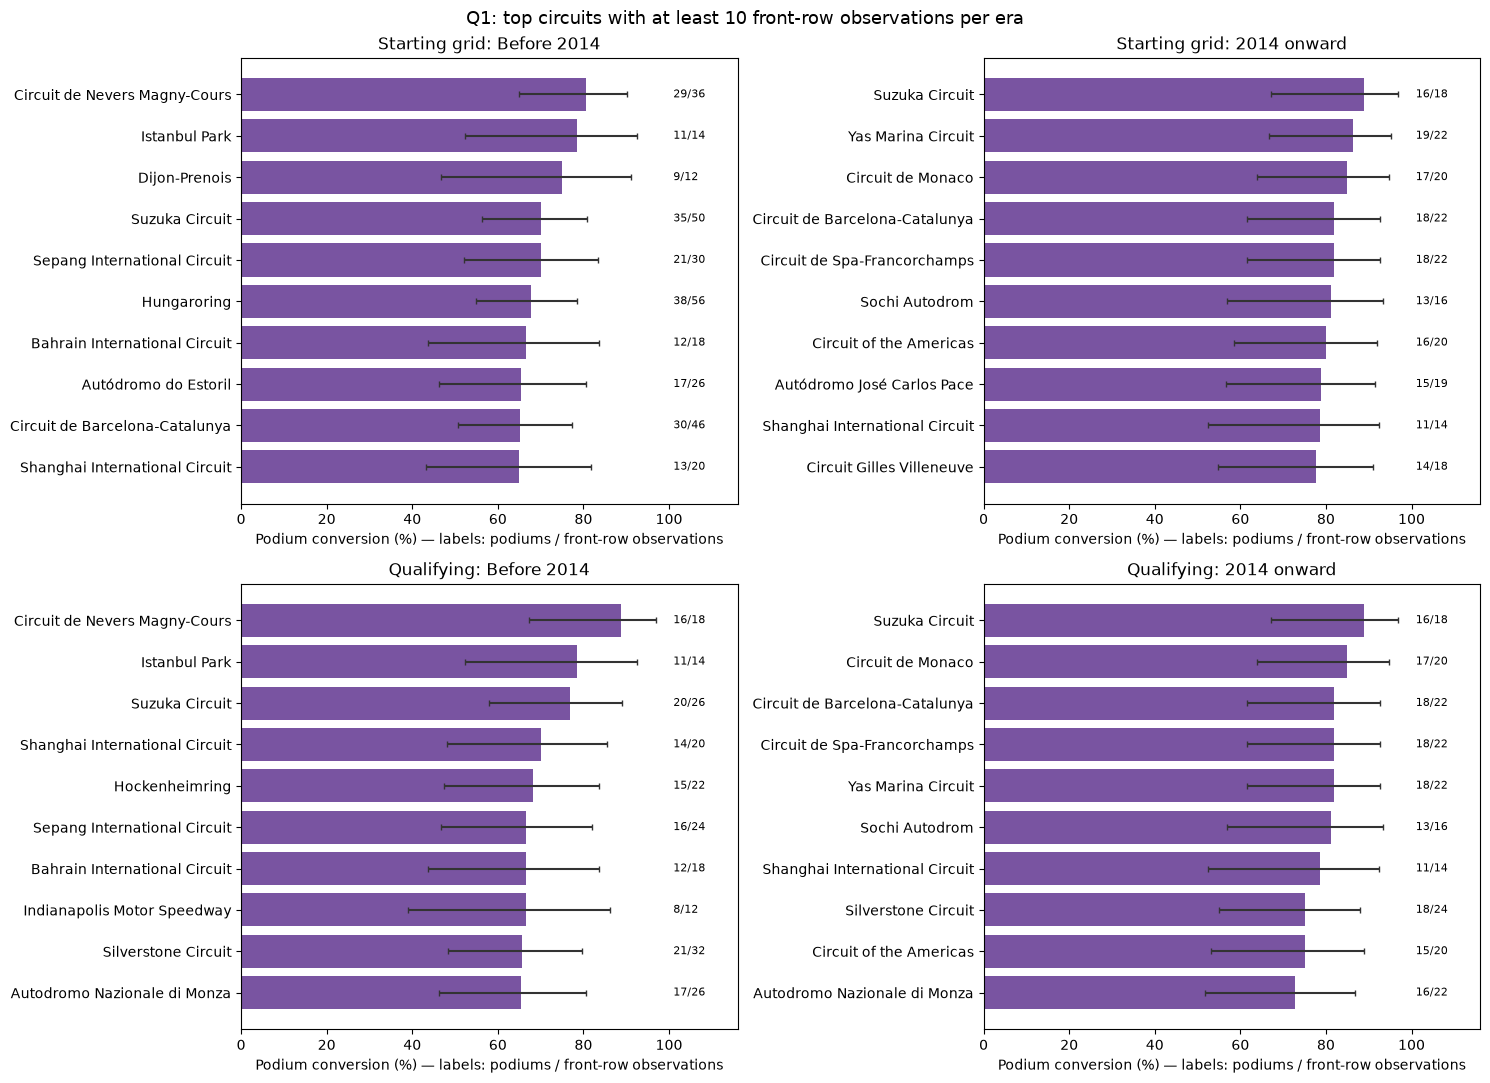

era,circuitId,circuit,2014 onward,Before 2014,rank_before,rank_after,rank_improvement,change_pp,definition
28,22,Suzuka Circuit,0.888889,0.769231,1.0,1.0,0.0,11.965812,Qualifying
19,6,Circuit de Monaco,0.850000,0.642857,7.0,2.0,5.0,20.714286,Qualifying
18,4,Circuit de Barcelona-Catalunya,0.818182,0.633333,8.0,3.0,5.0,18.484848,Qualifying
23,13,Circuit de Spa-Francorchamps,0.818182,0.541667,13.0,3.0,10.0,27.651515,Qualifying
29,24,Yas Marina Circuit,0.818182,0.600000,9.0,3.0,6.0,21.818182,Qualifying
26,17,Shanghai International Circuit,0.785714,0.700000,2.0,6.0,-4.0,8.571429,Qualifying
21,9,Silverstone Circuit,0.750000,0.656250,4.0,7.0,-3.0,9.375000,Qualifying
24,14,Autodromo Nazionale di Monza,0.727273,0.653846,5.0,8.0,-3.0,7.342657,Qualifying
16,1,Albert Park Grand Prix Circuit,0.722222,0.531250,14.0,9.0,5.0,19.097222,Qualifying
20,7,Circuit Gilles Villeneuve,0.722222,0.576923,12.0,9.0,3.0,14.529915,Qualifying


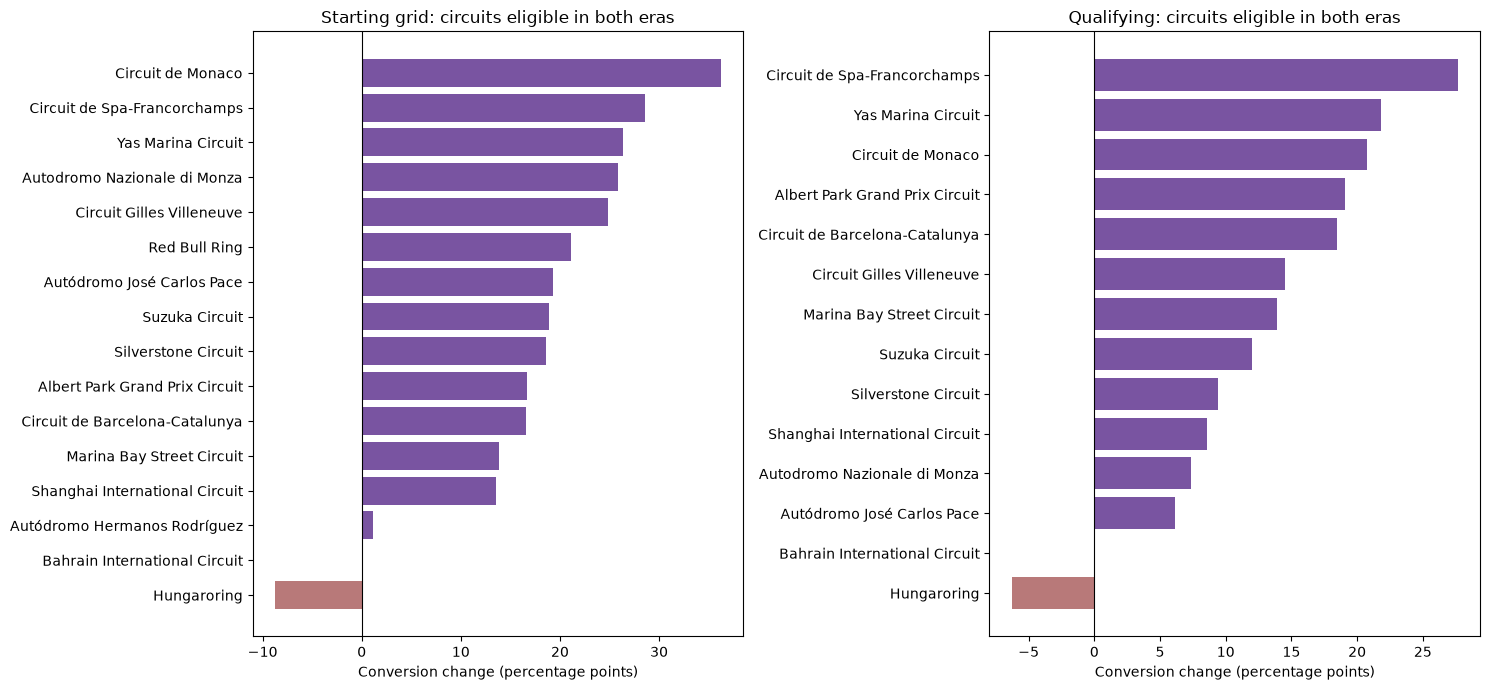

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for row, definition in enumerate(["Starting grid", "Qualifying"]):
    for col, era in enumerate(["Before 2014", "2014 onward"]):
        ax = axes[row, col]
        top = (q1_rates.loc[q1_rates["definition"].eq(definition) & q1_rates["era"].eq(era) & q1_rates["eligible"]]
               .sort_values(["conversion_rate", "front_row_observations", "circuit"], ascending=[False, False, True]).head(10)
               .iloc[::-1])
        if top.empty:
            ax.text(.5, .5, "No eligible circuits", ha="center")
            continue
        x = top["conversion_rate"].to_numpy() * 100
        ax.barh(top["circuit"], x, color="#7954a1")
        ax.errorbar(x, top["circuit"], xerr=np.vstack([x-top["ci_low"].to_numpy()*100,
                    top["ci_high"].to_numpy()*100-x]), fmt="none", ecolor="#333333", capsize=2)
        for i, (_, r) in enumerate(top.iterrows()):
            ax.text(101, i, f"{int(r.podiums)}/{int(r.front_row_observations)}", va="center", fontsize=8)
        ax.set_xlim(0, 116)
        ax.set_title(f"{definition}: {era}")
        ax.set_xlabel("Podium conversion (%) — labels: podiums / front-row observations")
fig.suptitle(f"Q1: top circuits with at least {MIN_FRONT_ROW} front-row observations per era", fontsize=13)
fig.tight_layout()
save_plot("08_q1_circuit_conversion_rankings.png")

q1_rank_changes = []
for definition in ["Starting grid", "Qualifying"]:
    eligible = q1_rates.loc[q1_rates["definition"].eq(definition) & q1_rates["eligible"]]
    wide = eligible.pivot(index=["circuitId", "circuit"], columns="era", values="conversion_rate").dropna()
    if wide.empty:
        continue
    wide["rank_before"] = wide["Before 2014"].rank(ascending=False, method="min")
    wide["rank_after"] = wide["2014 onward"].rank(ascending=False, method="min")
    wide["rank_improvement"] = wide["rank_before"] - wide["rank_after"]
    wide["change_pp"] = (wide["2014 onward"] - wide["Before 2014"]) * 100
    wide["definition"] = definition
    q1_rank_changes.append(wide.reset_index())
q1_rank_changes = pd.concat(q1_rank_changes, ignore_index=True) if q1_rank_changes else pd.DataFrame()
display(q1_rank_changes.sort_values(["definition", "rank_after"]))
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for ax, definition in zip(axes, ["Starting grid", "Qualifying"]):
    data = q1_rank_changes.loc[q1_rank_changes["definition"].eq(definition)].sort_values("change_pp")
    ax.barh(data["circuit"], data["change_pp"], color=np.where(data["change_pp"] >= 0, "#7954a1", "#b87979"))
    ax.axvline(0, color="black", linewidth=.8)
    ax.set(title=f"{definition}: circuits eligible in both eras", xlabel="Conversion change (percentage points)")
fig.tight_layout()
save_plot("09_q1_same_circuit_era_changes.png")


In [32]:
interpretation = ["### Q1 — Computed answer and interpretation"]
for definition in ["Starting grid", "Qualifying"]:
    for era in ["Before 2014", "2014 onward"]:
        eligible = q1_rates.loc[q1_rates["definition"].eq(definition) & q1_rates["era"].eq(era) & q1_rates["eligible"]]
        if eligible.empty:
            interpretation.append(f"- **{definition}, {era}:** no eligible circuits at the selected minimum.")
            continue
        best = eligible["conversion_rate"].max()
        leaders = eligible.loc[np.isclose(eligible["conversion_rate"], best)]
        labels = [f"{r.circuit}: {r.conversion_rate:.1%} ({int(r.podiums)}/{int(r.front_row_observations)})" for r in leaders.itertuples()]
        interpretation.append(f"- **{definition}, {era}:** highest observed conversion: " + "; ".join(labels) + ".")
    changes = q1_rank_changes.loc[q1_rank_changes["definition"].eq(definition)]
    changed = int(changes["rank_before"].ne(changes["rank_after"]).sum())
    interpretation.append(f"- **{definition}, rank comparison:** {changed} of {len(changes)} common eligible circuits change rank (ties use competition ranking).")
    if not changes.empty:
        biggest = changes.loc[changes["change_pp"].abs().idxmax()]
        interpretation.append(f"  Largest absolute conversion change among those circuits: {biggest['circuit']}, {biggest['change_pp']:+.1f} percentage points.")
interpretation += ["", "**Interpretation and limits:** these are historical associations, not causal circuit effects. Driver and constructor strength, era composition, race counts and missing qualifying coverage differ. Wilson intervals are approximate: the two front-row drivers share a race, so observations are not fully independent. Sparse samples and overlapping intervals limit confidence in exact rankings. Qualifying and grid must remain distinct; neither measure's missing values are substituted with the other. The before-2014 comparison covers much more history, and the post-2014 sample ends at the dataset's latest season.",
                  "", "**Pre-race cutoff:** Q1 outcomes are used only as historical analysis labels. For later prediction, derive any circuit conversion feature from prior races only; do not merge this full-history outcome aggregate into every modeling row."]
q1_interpretation = "\n".join(interpretation)
display(Markdown(q1_interpretation))

sensitivity = []
for minimum in [4, 10, 20]:
    for (definition, era), group in q1_rates.groupby(["definition", "era"]):
        eligible = group.loc[group["front_row_observations"].ge(minimum)]
        if not eligible.empty:
            best = eligible["conversion_rate"].max()
            leaders = eligible.loc[np.isclose(eligible["conversion_rate"], best), "circuit"].tolist()
            sensitivity.append({"minimum_observations": minimum, "definition": definition, "era": era,
                                "eligible_circuits": len(eligible), "leaders": "; ".join(leaders), "best_rate": best})
display(pd.DataFrame(sensitivity))


### Q1 — Computed answer and interpretation
- **Starting grid, Before 2014:** highest observed conversion: Circuit de Nevers Magny-Cours: 80.6% (29/36).
- **Starting grid, 2014 onward:** highest observed conversion: Suzuka Circuit: 88.9% (16/18).
- **Starting grid, rank comparison:** 14 of 16 common eligible circuits change rank (ties use competition ranking).
  Largest absolute conversion change among those circuits: Circuit de Monaco, +36.2 percentage points.
- **Qualifying, Before 2014:** highest observed conversion: Circuit de Nevers Magny-Cours: 88.9% (16/18).
- **Qualifying, 2014 onward:** highest observed conversion: Suzuka Circuit: 88.9% (16/18).
- **Qualifying, rank comparison:** 13 of 14 common eligible circuits change rank (ties use competition ranking).
  Largest absolute conversion change among those circuits: Circuit de Spa-Francorchamps, +27.7 percentage points.

**Interpretation and limits:** these are historical associations, not causal circuit effects. Driver and constructor strength, era composition, race counts and missing qualifying coverage differ. Wilson intervals are approximate: the two front-row drivers share a race, so observations are not fully independent. Sparse samples and overlapping intervals limit confidence in exact rankings. Qualifying and grid must remain distinct; neither measure's missing values are substituted with the other. The before-2014 comparison covers much more history, and the post-2014 sample ends at the dataset's latest season.

**Pre-race cutoff:** Q1 outcomes are used only as historical analysis labels. For later prediction, derive any circuit conversion feature from prior races only; do not merge this full-history outcome aggregate into every modeling row.

,minimum_observations,definition,era,eligible_circuits,leaders,best_rate
0,4,Qualifying,2014 onward,30,Autódromo Internacional do Algarve; Miami Inte...,1.000000
1,4,Qualifying,Before 2014,31,Circuit of the Americas,1.000000
2,4,Starting grid,2014 onward,30,Autódromo Internacional do Algarve; Miami Inte...,1.000000
3,4,Starting grid,Before 2014,59,Circuit of the Americas,1.000000
4,10,Qualifying,2014 onward,19,Suzuka Circuit,0.888889
5,10,Qualifying,Before 2014,22,Circuit de Nevers Magny-Cours,0.888889
6,10,Starting grid,2014 onward,19,Suzuka Circuit,0.888889
7,10,Starting grid,Before 2014,45,Circuit de Nevers Magny-Cours,0.805556
8,20,Qualifying,2014 onward,11,Circuit de Monaco,0.850000
9,20,Qualifying,Before 2014,15,Suzuka Circuit,0.769231


## 11. Person 1 handoff

`tables_clean` remains the same dictionary produced by the original cells. Other team members can use it as before. The appended Q1 analysis reads the cleaned tables but does not modify them. `clean_tables(tables_raw)` is now available for reuse.

Q1's full tables, figures and written interpretation are saved below for the team's report. These outcome-based historical summaries are analysis outputs, not current-race predictive features.

All ten cleaning/Q1 figures are saved as PNGs in `OUTPUT_DIR`, along with both conversion audits. `races.year -> seasons.year` is included in foreign-key validation. The reusable cleaner includes the completed numeric/timing conversions. Set `F1_DATA_DIR` and optionally `F1_OUTPUT_DIR` to run locally.


In [33]:
q1_rates.to_csv(OUTPUT_DIR / "q1_all_circuit_rates.csv", index=False)
q1_rank_changes.to_csv(OUTPUT_DIR / "q1_common_circuit_rank_changes.csv", index=False)
q1_coverage.to_csv(OUTPUT_DIR / "q1_coverage.csv")
(OUTPUT_DIR / "q1_interpretation.md").write_text(q1_interpretation, encoding="utf-8")
print("Person 1 additions complete. Existing tables_clean preserved.")

plot_manifest = pd.DataFrame({"plot_file": sorted(p.name for p in OUTPUT_DIR.glob("*.png"))})
plot_manifest.to_csv(OUTPUT_DIR / "plot_manifest.csv", index=False)
assert len(plot_manifest) == 10, "Expected all ten cleaning and Q1 plots"
display(plot_manifest)


Person 1 additions complete. Existing tables_clean preserved.


,plot_file
0,01_raw_table_sizes.png
1,02_raw_missing_sentinels.png
2,03_duplicate_groups_by_year.png
3,04_sentinels_before_after.png
4,05_duplicates_before_after.png
5,08_q1_circuit_conversion_rankings.png
6,09_q1_same_circuit_era_changes.png
7,calculated_duplicate_checks.png
8,distributions_before_after.png
9,missingness_before_after.png
